# 01 · BTS On-Time: EDA and propagation prototype
Input: the Parquet files written by `00_download_bts.ipynb` (≈105.6M flights, 2010-01 → 2026-08)

Covers: shape and null rates, tail-number coverage (the delay chain depends on it), delay distribution and outliers, delay by hour and airport, and a first propagation number.

In [13]:
import os
from pathlib import Path
import duckdb, pandas as pd
import matplotlib.pyplot as plt

DATA = Path(os.path.expanduser("~/Desktop/ADSP32030_Scalable/Project/data/flights"))
PQ = DATA/"parquet"
PROTO_YEAR = 2024        # the propagation prototype runs on one year; Spark will do all years

con = duckdb.connect()
con.execute("SET memory_limit='8GB'")                       # leave RAM for the notebook
con.execute(f"SET temp_directory='{DATA/'duckdb_tmp'}'")    # spill to disk if a query needs more
con.execute(f"CREATE OR REPLACE VIEW f AS SELECT * FROM read_parquet('{PQ}/*.parquet')")
print(len(list(PQ.glob('*.parquet'))), "monthly Parquet files")

200 monthly Parquet files


## 1 · Shape, columns, nulls

In [14]:
print(con.execute("SELECT count(*) AS rows, count(DISTINCT Tail_Number) AS tails, "
                  "min(FlightDate) AS first_day, max(FlightDate) AS last_day FROM f").df())
cols = [r[0] for r in con.execute("DESCRIBE f").fetchall()]
nulls = con.execute("SELECT " + ", ".join(f'100.0*avg(("{c}" IS NULL)::int) AS "{c}"' for c in cols) + " FROM f").df().T
nulls.columns = ["pct_null"]
nulls.sort_values("pct_null", ascending=False).head(15)

        rows  tails  first_day   last_day
0  105631230  11509 2010-01-01 2026-08-31


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,pct_null
CancellationCode,98.127985
LateAircraftDelay,81.175591
SecurityDelay,81.175591
NASDelay,81.175591
WeatherDelay,81.175591
CarrierDelay,81.175591
ArrDel15,2.114719
ArrDelay,2.114719
AirTime,2.114389
ActualElapsedTime,2.114389


In [15]:
# Tail-number coverage (the propagation chain depends on it)
con.execute("SELECT 100.0*avg((Tail_Number IS NULL OR Tail_Number='')::int) AS pct_missing_tail, "
            "100.0*avg(Cancelled) AS pct_cancelled, 100.0*avg(Diverted) AS pct_diverted FROM f").df()

,pct_missing_tail,pct_cancelled,pct_diverted
0,0.420297,1.872015,0.24238


## 2 · Distributions and outliers

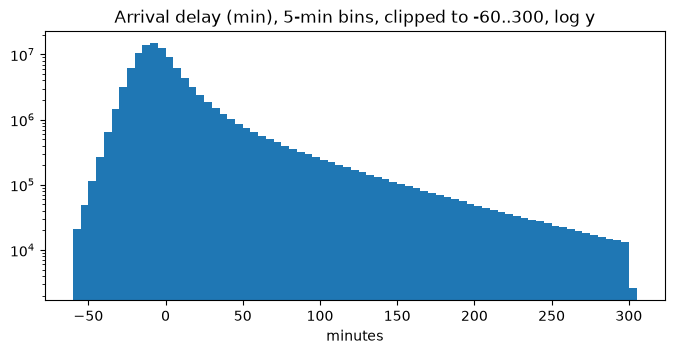

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                            q  max_delay  min_delay
0  [-5.0, 37.0, 183.0, 513.0]     4405.0     -411.0


In [16]:
# bin in DuckDB (105M rows: never pull them into pandas)
h = con.execute("""SELECT CAST(floor(ArrDelay/5)*5 AS INT) AS bin, count(*) AS n
                   FROM f WHERE ArrDelay BETWEEN -60 AND 300 GROUP BY 1 ORDER BY 1""").df()
plt.figure(figsize=(8,3.5)); plt.bar(h.bin, h.n, width=5, align="edge"); plt.yscale("log")
plt.title("Arrival delay (min), 5-min bins, clipped to -60..300, log y"); plt.xlabel("minutes"); plt.show()
print(con.execute("SELECT quantile_cont(ArrDelay,[0.5,0.9,0.99,0.999]) AS q, max(ArrDelay) AS max_delay, min(ArrDelay) AS min_delay FROM f").df())

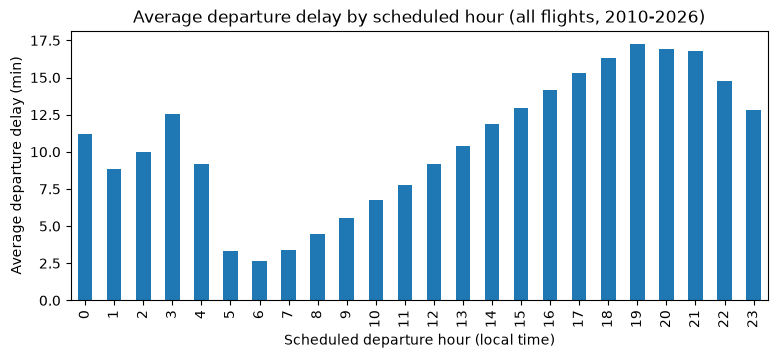

In [23]:
by_hour = con.execute("""SELECT CAST(CRSDepTime/100 AS INT) % 24 AS hr,      -- % 24 folds 2400 (midnight) into hour 0
                                avg(DepDelay) AS avg_dep_delay, count(*) AS flights
                         FROM f
                         WHERE DepDelay IS NOT NULL AND CRSDepTime IS NOT NULL   -- drops 1 flight with no scheduled time (2012, WN)
                         GROUP BY 1 ORDER BY 1""").df()
ax = by_hour.plot(x="hr", y="avg_dep_delay", kind="bar", figsize=(9,3.5), legend=False,
                  title="Average departure delay by scheduled hour (all flights, 2010-2026)")
ax.set_xlabel("Scheduled departure hour (local time)"); ax.set_ylabel("Average departure delay (min)")
plt.show()

In [18]:
print(con.execute("""SELECT count(*) AS n, round(avg(DepDelay)) AS avg_delay,
                     min(Year) AS first_year, max(Year) AS last_year
                     FROM f WHERE CRSDepTime IS NULL AND DepDelay IS NOT NULL""").df())
con.execute("""SELECT Year, Reporting_Airline, count(*) AS n FROM f
               WHERE CRSDepTime IS NULL AND DepDelay IS NOT NULL
               GROUP BY 1, 2 ORDER BY n DESC LIMIT 10""").df()

   n  avg_delay  first_year  last_year
0  1      548.0      2012.0     2012.0


,Year,Reporting_Airline,n
0,2012.0,WN,1


In [19]:
con.execute("""
SELECT count(*) FILTER (WHERE CRSDepTime IS NULL)                                   AS null_crs_all_rows,
       count(*) FILTER (WHERE CRSDepTime IS NULL AND DepDelay IS NOT NULL)          AS null_crs_with_delay,
       count(*) FILTER (WHERE CAST(CRSDepTime/100 AS INT) IS NULL
                          AND DepDelay IS NOT NULL)                                 AS na_bar_rows
FROM f""").df()

,null_crs_all_rows,null_crs_with_delay,na_bar_rows
0,1,1,1


In [20]:
top = con.execute("""SELECT Origin, count(*) AS flights, avg(DepDelay) AS avg_dep_delay,
                      avg(DepDel15)*100 AS pct_late15 FROM f GROUP BY 1 HAVING count(*)>5000
                      ORDER BY avg_dep_delay DESC LIMIT 15""").df()
top

,Origin,flights,avg_dep_delay,pct_late15
0,OTH,8438,26.862031,34.436923
1,CEC,5177,25.841481,37.382983
2,HTS,5008,24.824162,33.347125
3,SCK,5697,22.755523,32.144151
4,CKB,5484,22.419452,22.380774
5,USA,8250,21.453087,30.133673
6,LCK,9285,20.811493,28.420585
7,BLV,10124,20.609483,27.360602
8,MVY,8892,20.427839,25.891816
9,ASE,95126,19.628442,25.593009


## 3 · First propagation prototype (check-in result)
Chain each tail number's flights in time order and carry the previous flight's arrival delay into the next departure.
**Prototype only (one year, set by `PROTO_YEAR`):** it orders by date + local departure time. The final version needs UTC timestamps and the scheduled turnaround buffer. Spark's `lag` window does the same thing at full scale.

In [21]:
con.execute(f"""
CREATE OR REPLACE TABLE chain AS
SELECT Tail_Number, FlightDate, Origin, Dest, CRSDepTime, DepDelay, ArrDelay,
       lag(ArrDelay) OVER w AS prev_arr_delay,
       lag(Dest)     OVER w AS prev_dest
FROM f
WHERE Year = {PROTO_YEAR} AND Tail_Number IS NOT NULL AND Tail_Number<>'' AND Cancelled=0 AND Diverted=0
WINDOW w AS (PARTITION BY Tail_Number ORDER BY FlightDate, CRSDepTime)
""")
con.execute("""SELECT count(*) AS linked_pairs,
       avg(DepDelay) FILTER (WHERE prev_arr_delay>=15) AS avg_dep_delay_after_late_inbound,
       avg(DepDelay) FILTER (WHERE prev_arr_delay<15)  AS avg_dep_delay_after_ontime_inbound
FROM chain WHERE prev_dest=Origin""").df()

,linked_pairs,avg_dep_delay_after_late_inbound,avg_dep_delay_after_ontime_inbound
0,6817265,39.098335,3.694102


In [22]:
# Sanity check against BTS's own cause field (the "ask it twice" idea)
con.execute("SELECT avg(LateAircraftDelay) AS avg_late_aircraft_min, "
            "100.0*avg((LateAircraftDelay>0)::int) AS pct_flights_with_late_aircraft FROM f WHERE ArrDelay>=15").df()

,avg_late_aircraft_min,pct_flights_with_late_aircraft
0,25.303271,51.408761
